# 🏪 6-7 Store — Analytical Results Report: Test vs. Control
### Statistical Evaluation, Fit Metrics, and Parallel-Trends Diagnostics

*Notebook 2 of 2 · Previous: [`optimization.ipynb`](optimization.ipynb) (MILP model and solver run)*

---

> **Purpose of this notebook:**
> This notebook evaluates the **test and control store groups** produced by the combinatorial optimization algorithm (MILP via PuLP).
>
> It shows, visually and quantitatively, how closely the control group reproduces the test group's temporal, geographic, and seasonal behavior. It is written for both **technical reviewers** and **pricing leadership**.
>
> *The saved outputs come from a run on a single state (Florida): 28 test stores vs. 28 control stores, over 321 days.*
>
> *Visual identity inspired by the 7-Eleven convenience chain (#008163 emerald green, #EE6723 citrus orange, #EE2726 red).*

In [1]:
# Setup and analytical library imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

import warnings
warnings.filterwarnings('ignore')

# Visual style settings
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# 7-Eleven-inspired colors
PALETTE = {
    'test': '#008163',       # Emerald green
    'control': '#EE6723',    # Citrus orange
    'total': '#64748B',      # Neutral gray
    'accent': '#EE2726',     # Red
    'dark': '#1E293B'        # Dark slate
}

## 1. Loading the Data and Auditing the Experimental Groups

We load the dataset produced by the optimizer (`output_data/df_results.parquet`). The expected columns are:
`['dt_ref', 'store_id', 'state', 'sales_region', 'net_sales', 'gross_sales', 'qty_sold', 'flag']`.

In [2]:
# Read the consolidated data
data_path = 'output_data/df_results.parquet'

df_results = pd.read_parquet(data_path, engine='pyarrow')
df_results['dt_ref'] = pd.to_datetime(df_results['dt_ref'])

# Group summary
stores_count = df_results.groupby('flag', dropna=False)['store_id'].nunique()
total_stores = df_results['store_id'].nunique()
n_test = stores_count.get('test', 0)
n_control = stores_count.get('control', 0)
n_unselected = total_stores - n_test - n_control

print('=== 6-7 STORE EXPERIMENT AUDIT ===')
print(f'Total stores in the network: {total_stores:,}')
print(f'Test group stores: {n_test:,} ({n_test/total_stores*100:.1f}%)')
print(f'Control group stores: {n_control:,} ({n_control/total_stores*100:.1f}%)')
print(f'Unselected stores: {n_unselected:,} ({n_unselected/total_stores*100:.1f}%)')
print(f'Historical period: {df_results["dt_ref"].min().strftime("%Y-%m-%d")} to {df_results["dt_ref"].max().strftime("%Y-%m-%d")} ({df_results["dt_ref"].nunique()} days)')
print(f'States: {df_results["state"].nunique()} | Sales regions: {df_results["sales_region"].unique().tolist()}')

display(df_results.head(5))

=== 6-7 STORE EXPERIMENT AUDIT ===
Total stores in the network: 2,046
Test group stores: 494 (24.1%)
Control group stores: 494 (24.1%)
Unselected stores: 1,058 (51.7%)
Historical period: 2026-01-01 to 2026-11-17 (321 days)
States: 50 | Sales regions: ['Northeast', 'Midwest', 'South', 'West']


,dt_ref,store_id,state,sales_region,net_sales,gross_sales,qty_sold,flag,processing_datetime
0,2026-01-01,STORE-0067,New York,Northeast,36361.1600,42056.2800,4019,None,NaT
1,2026-01-01,STORE-0074,New York,Northeast,54537.8000,66148.3700,4312,test,2026-11-24 06:03:22.372382-06:00
2,2026-01-01,STORE-0264,Michigan,Midwest,6662.8400,7734.3500,567,None,NaT
3,2026-01-01,STORE-0307,Connecticut,Northeast,15012.8300,19541.2900,2383,control,2026-11-24 05:46:18.242258-06:00
4,2026-01-01,STORE-0384,New York,Northeast,36296.3600,44760.8800,3033,None,NaT


## 2. Machine Learning Metrics and Statistical Validation

To rigorously quantify how closely the control group tracks the test group, we evaluate a broad set of daily-level metrics:
- **MAE (Mean Absolute Error):** Average daily absolute error.
- **RMSE (Root Mean Squared Error):** Penalizes larger deviations more heavily.
- **MAPE (Mean Absolute Percentage Error):** Average daily percentage error.
- **WAPE (Weighted Absolute Percentage Error):** A retail industry standard. It weights errors by total volume, avoiding distortions on low-traffic days.
- **$R^2$ Score (Coefficient of Determination):** Share of the test group's variance explained by the control group.
- **Pearson Correlation ($r$):** Daily linear co-movement.
- **Spearman Correlation ($\rho$):** Daily monotonic (rank-based) co-movement.
- **Kolmogorov-Smirnov Test (2-Sample KS):** Tests whether the daily empirical distributions are statistically equivalent ($p > 0.05$ indicates no significant difference).

In [3]:
def evaluate_test_control_performance(df: pd.DataFrame) -> pd.DataFrame:
    """
    Computes detailed statistical and machine learning metrics between the test and control groups.
    """
    df_tc = df[df['flag'].isin(['test', 'control'])].copy()

    # Daily aggregation by group
    daily = df_tc.groupby(['dt_ref', 'flag']).agg({
        'qty_sold': 'sum',
        'net_sales': 'sum',
        'gross_sales': 'sum'
    }).reset_index()

    piv = daily.pivot(index='dt_ref', columns='flag')

    metrics_list = []
    target_cols = ['qty_sold', 'net_sales', 'gross_sales']

    for col in target_cols:
        test_s = piv[(col, 'test')]
        ctrl_s = piv[(col, 'control')]

        diff = test_s - ctrl_s
        abs_diff = diff.abs()

        mae = abs_diff.mean()
        rmse = np.sqrt((diff**2).mean())
        mape = (abs_diff / test_s.replace(0, np.nan)).mean() * 100
        wape = (abs_diff.sum() / test_s.sum()) * 100

        # R2 score
        ss_res = (diff**2).sum()
        ss_tot = ((test_s - test_s.mean())**2).sum()
        r2 = 1 - (ss_res / ss_tot)

        # Correlations
        pearson_r, pearson_p = stats.pearsonr(test_s, ctrl_s)
        spearman_rho, spearman_p = stats.spearmanr(test_s, ctrl_s)

        # KS test (2-sample)
        ks_stat, ks_p = stats.ks_2samp(test_s, ctrl_s)

        metrics_list.append({
            'Metric': col,
            'Test Mean': test_s.mean(),
            'Control Mean': ctrl_s.mean(),
            'Mean Difference (%)': ((test_s.mean() - ctrl_s.mean()) / ctrl_s.mean()) * 100,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE (%)': mape,
            'WAPE (%)': wape,
            'R² Score': r2,
            'Pearson r': pearson_r,
            'Spearman ρ': spearman_rho,
            'KS p-value': ks_p
        })

    return pd.DataFrame(metrics_list)

df_metrics_summary = evaluate_test_control_performance(df_results)
display(df_metrics_summary.style.highlight_max(subset=['R² Score', 'Pearson r', 'Spearman ρ'], color='#DCFCE7'))

,Metric,Test Mean,Control Mean,Mean Difference (%),MAE,RMSE,MAPE (%),WAPE (%),R² Score,Pearson r,Spearman ρ,KS p-value
0,qty_sold,1418536.514019,1378742.996885,2.886217,43431.392523,61134.952558,2.904923,3.061704,0.985931,0.996778,0.993508,0.284883
1,net_sales,11338398.089377,11136676.902648,1.811323,242905.398069,323294.949163,2.090203,2.142326,0.994270,0.998738,0.995736,0.498713
2,gross_sales,13665745.177975,13427468.082991,1.774550,289703.624081,383534.019809,2.070202,2.119926,0.994414,0.998735,0.995859,0.562307


## 3. Daily Performance Time Series (Interactive Plotly)

We compare the daily evolution of the three main metrics (`qty_sold`, `net_sales`, and `gross_sales`) across the 321 days of the 2026 sample period.

#### Seaborn

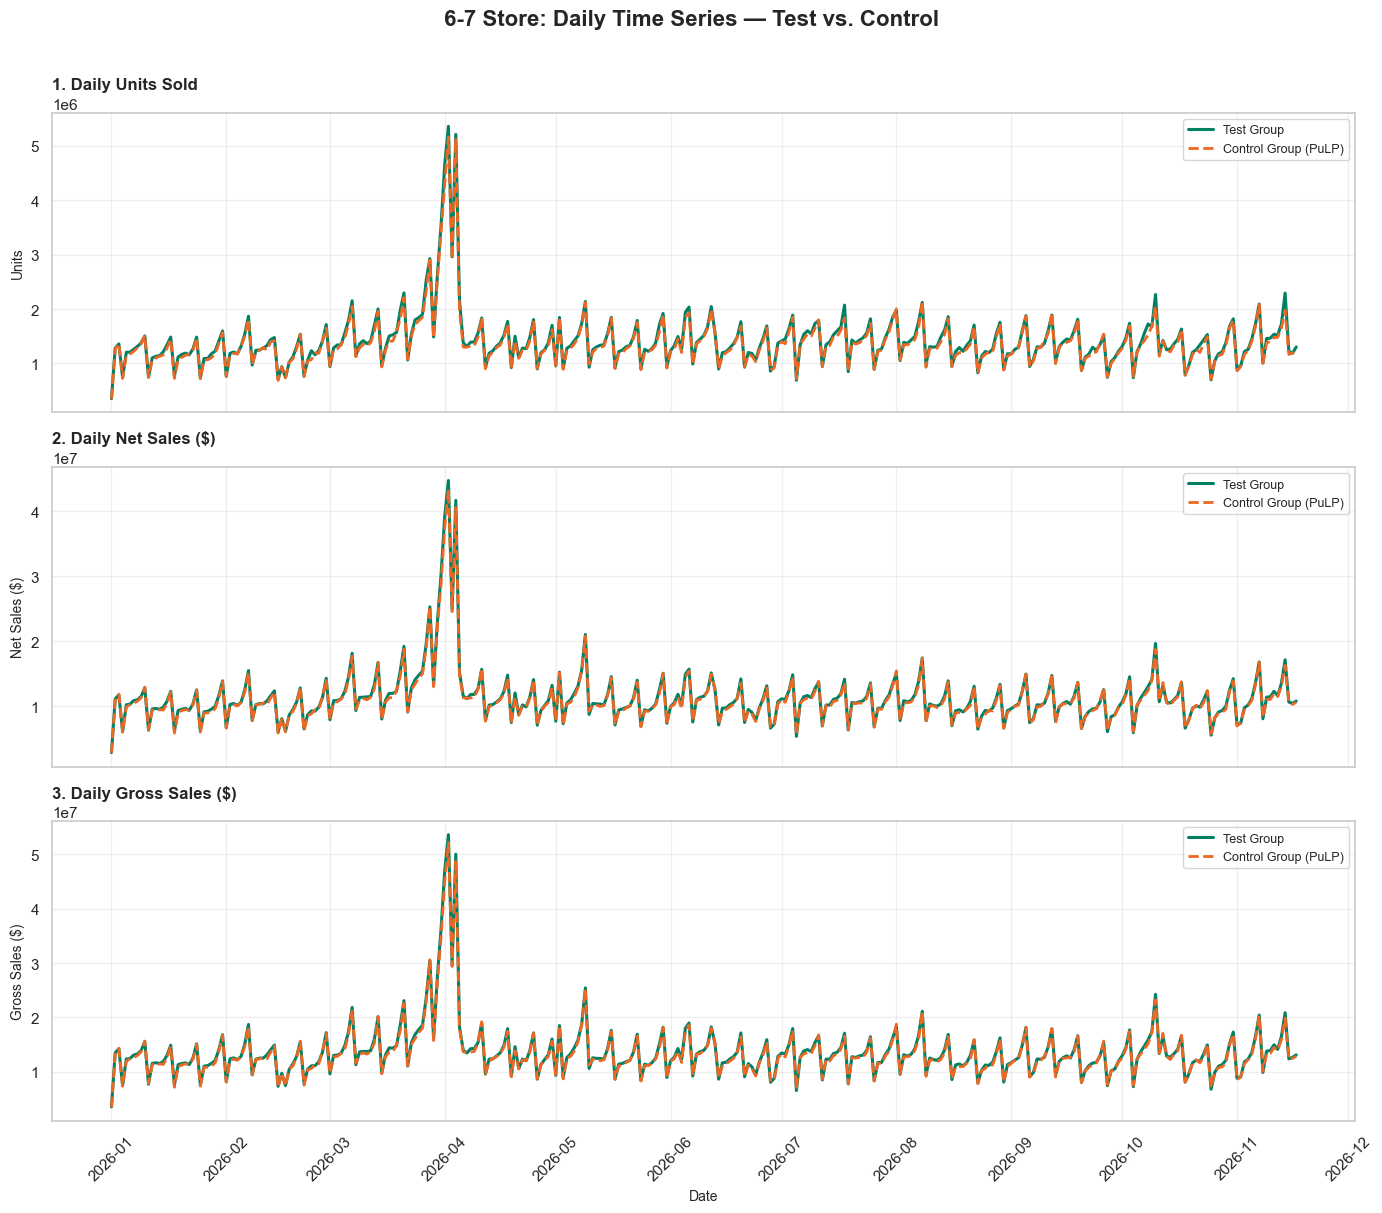

In [4]:
# Daily aggregation for the charts
df_tc = df_results[df_results['flag'].isin(['test', 'control'])].copy()
daily_agg = (df_tc.groupby(['dt_ref', 'flag'])[['net_sales', 'gross_sales', 'qty_sold']].sum().reset_index())

# Chart configuration
sns.set_theme(style='whitegrid', context='notebook')

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 12), sharex=True)

metrics_info = [
    ('qty_sold', '1. Daily Units Sold', 'Units'),
    ('net_sales', '2. Daily Net Sales ($)', 'Net Sales ($)'),
    ('gross_sales', '3. Daily Gross Sales ($)', 'Gross Sales ($)')
]

for ax, (col_name, title, ylabel) in zip(axes, metrics_info):
    # Test Group
    sns.lineplot(data=daily_agg[daily_agg['flag'] == 'test'], x='dt_ref', y=col_name, ax=ax, color=PALETTE['test'], linewidth=2.2, label='Test Group')

    # Control Group
    sns.lineplot(data=daily_agg[daily_agg['flag'] == 'control'], x='dt_ref', y=col_name, ax=ax, color=PALETTE['control'], linewidth=2.0, linestyle='--', label='Control Group (PuLP)')

    ax.set_title(title, fontsize=12, fontweight='bold', loc='left')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel('')
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(True, alpha=0.3)

# General layout
fig.suptitle('6-7 Store: Daily Time Series — Test vs. Control', fontsize=16, fontweight='bold', y=1.01)
axes[-1].set_xlabel('Date', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Plotly

In [5]:
# Daily aggregation for the charts
df_tc = df_results[df_results['flag'].isin(['test', 'control'])].copy()
daily_agg = df_tc.groupby(['dt_ref', 'flag'])[['net_sales', 'gross_sales', 'qty_sold']].sum().reset_index()

daily_piv = daily_agg.pivot(index='dt_ref', columns='flag')

# Chart with 3 subplots
fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.08,
    subplot_titles=(
        '<b>1. Daily Units Sold</b>',
        '<b>2. Daily Net Sales ($)</b>',
        '<b>3. Daily Gross Sales ($)</b>'
    )
)

metrics_info = [
    ('qty_sold', 1, 'Units'),
    ('net_sales', 2, 'Net Sales ($)'),
    ('gross_sales', 3, 'Gross Sales ($)')
]

for col_name, row_idx, label in metrics_info:
    test_series = daily_piv[(col_name, 'test')]
    ctrl_series = daily_piv[(col_name, 'control')]

    fig.add_trace(
        go.Scatter(
            x=daily_piv.index, y=test_series, mode='lines',
            name='Test Group', line=dict(color=PALETTE['test'], width=2.2),
            legendgroup='test', showlegend=(row_idx == 1)
        ),
        row=row_idx, col=1
    )

    fig.add_trace(
        go.Scatter(
            x=daily_piv.index, y=ctrl_series, mode='lines',
            name='Control Group (PuLP)', line=dict(color=PALETTE['control'], width=2.0, dash='dash'),
            legendgroup='control', showlegend=(row_idx == 1)
        ),
        row=row_idx, col=1
    )

    fig.update_yaxes(title_text=label, row=row_idx, col=1)

fig.update_layout(
    title=dict(text='<b>6-7 Store: Daily Time Series — Test vs. Control</b>', x=0.5, font=dict(size=16)),
    template='plotly_white',
    height=900,
    hovermode='x unified',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1)
)

fig.show()

## 4. Test & Control Groups vs. the Total 6-7 Network

To show how the experimental groups relate to the whole chain, we plot the daily series of the **total network** (all stores) alongside the test and control groups. Store counts are computed from the data.

#### Seaborn

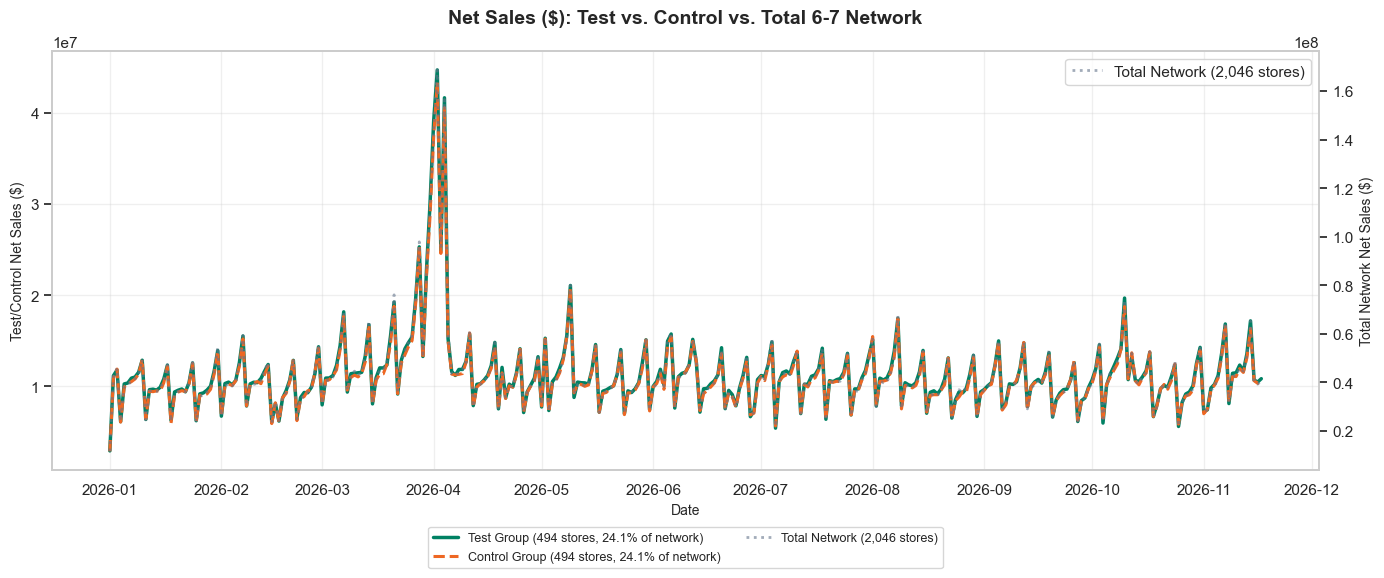

In [6]:
# Daily totals for the entire network
daily_total_network = (df_results.groupby('dt_ref').agg({'net_sales': 'sum', 'qty_sold': 'sum'}).reset_index())

# Chart configuration
sns.set_theme(style='whitegrid', context='notebook')

fig, ax1 = plt.subplots(figsize=(14, 6))

# Secondary axis
ax2 = ax1.twinx()

# Total Network on the secondary axis
sns.lineplot(data=daily_total_network, x='dt_ref', y='net_sales', ax=ax2, color=PALETTE['total'], linewidth=2, linestyle=':', alpha=0.6, label=f'Total Network ({total_stores:,} stores)')

# Test Group on the primary axis
sns.lineplot(data=daily_agg[daily_agg['flag'] == 'test'], x='dt_ref', y='net_sales', ax=ax1, color=PALETTE['test'], linewidth=2.5, label=f'Test Group ({n_test:,} stores, {n_test/total_stores*100:.1f}% of network)')

# Control Group on the primary axis
sns.lineplot(data=daily_agg[daily_agg['flag'] == 'control'], x='dt_ref', y='net_sales', ax=ax1, color=PALETTE['control'], linewidth=2.2, linestyle='--', label=f'Control Group ({n_control:,} stores, {n_control/total_stores*100:.1f}% of network)')

# Axis labels
ax1.set_xlabel('Date', fontsize=10)
ax1.set_ylabel('Test/Control Net Sales ($)', fontsize=10)
ax2.set_ylabel('Total Network Net Sales ($)', fontsize=10)

# Title
ax1.set_title('Net Sales ($): Test vs. Control vs. Total 6-7 Network', fontsize=14, fontweight='bold', pad=20)

# Combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=True, fontsize=9)

# Formatting
ax1.grid(True, alpha=0.3)
ax2.grid(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Plotly

In [7]:
# Daily totals for the entire network
daily_total_network = df_results.groupby('dt_ref').agg({ 'net_sales': 'sum', 'qty_sold': 'sum'}).reset_index()

# Chart with a secondary axis for the network total
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Network total on the secondary axis
fig.add_trace(go.Scatter(x=daily_total_network['dt_ref'], y=daily_total_network['net_sales'],name=f'Total Network ({total_stores:,} stores)', line=dict(color=PALETTE['total'], width=2, dash='dot'),opacity=0.6), secondary_y=True)

# Test and control groups on the primary axis
fig.add_trace(go.Scatter(x=daily_piv.index, y=daily_piv[('net_sales', 'test')],name=f'Test Group ({n_test:,} stores, {n_test/total_stores*100:.1f}% of network)', line=dict(color=PALETTE['test'], width=2.5)),secondary_y=False)
fig.add_trace(go.Scatter(x=daily_piv.index, y=daily_piv[('net_sales', 'control')],name=f'Control Group ({n_control:,} stores, {n_control/total_stores*100:.1f}% of network)', line=dict(color=PALETTE['control'], width=2.2, dash='dash')),secondary_y=False)
fig.update_layout(title=dict(text='<b>Net Sales ($): Test vs. Control vs. Total 6-7 Network</b>', x=0.5), template='plotly_white', height=550, hovermode='x unified', legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1))

fig.update_yaxes(title_text='Test/Control Net Sales ($)', secondary_y=False)
fig.update_yaxes(title_text='Total Network Net Sales ($)', secondary_y=True)
fig.show()

## 5. Residual, Spread, and Daily Percentage Change Analysis

We analyze the daily percentage variation $[(\text{Test}_t - \text{Control}_t) / \text{Control}_t] \times 100\%$ and the statistical distribution of the residuals (checking for symmetry and proximity to zero).

#### Seaborn

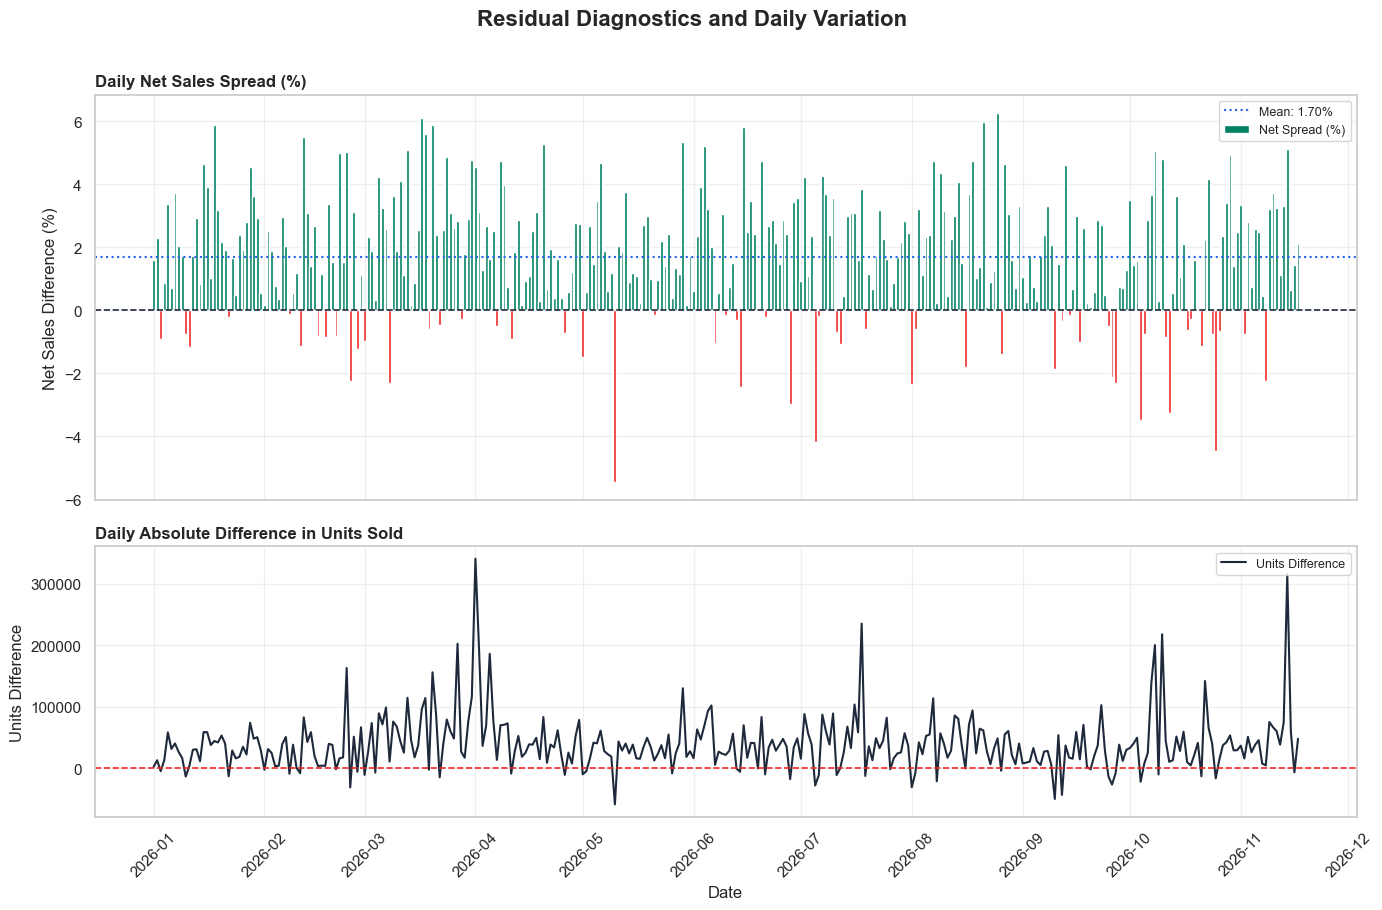

In [8]:
# 1. DAILY DIFFERENCE CALCULATIONS
df_diff = pd.DataFrame(index=daily_piv.index)

for m in ['qty_sold', 'net_sales', 'gross_sales']:
    df_diff[f'{m}_diff'] = (daily_piv[(m, 'test')] - daily_piv[(m, 'control')])
    df_diff[f'{m}_diff_pct'] = (df_diff[f'{m}_diff'] / daily_piv[(m, 'control')]) * 100

df_diff = df_diff.reset_index()

# 2. CHART CONFIGURATION
sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [0.6, 0.4]})

# 3. DAILY NET SALES SPREAD (%)
colors_spread = [PALETTE['test'] if x >= 0 else PALETTE['accent'] for x in df_diff['net_sales_diff_pct']]

axes[0].bar(df_diff['dt_ref'], df_diff['net_sales_diff_pct'], color=colors_spread, label='Net Spread (%)', width=0.8)

# Zero reference line
axes[0].axhline(y=0, color='#1E293B', linestyle='--', linewidth=1.2)

# Mean reference line
mean_spread = df_diff['net_sales_diff_pct'].mean()

axes[0].axhline(y=mean_spread, color='#2563EB', linestyle=':', linewidth=1.5, label=f'Mean: {mean_spread:.2f}%')
axes[0].set_title('Daily Net Sales Spread (%)', fontsize=12, fontweight='bold', loc='left')
axes[0].set_ylabel('Net Sales Difference (%)')
axes[0].legend(loc='upper right', fontsize=9)


# 4. DAILY ABSOLUTE DIFFERENCE IN UNITS SOLD
sns.lineplot(data=df_diff, x='dt_ref', y='qty_sold_diff', ax=axes[1], color=PALETTE['dark'], linewidth=1.5, label='Units Difference')

# Zero reference line
axes[1].axhline(y=0, color='#EE2726', linestyle='--', linewidth=1.2)
axes[1].set_title('Daily Absolute Difference in Units Sold', fontsize=12, fontweight='bold', loc='left')
axes[1].set_ylabel('Units Difference')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper right', fontsize=9)


# 5. GENERAL FORMATTING
fig.suptitle('Residual Diagnostics and Daily Variation', fontsize=16, fontweight='bold', y=1.01)

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Plotly

In [9]:
# Daily difference calculations
df_diff = pd.DataFrame(index=daily_piv.index)
for m in ['qty_sold', 'net_sales', 'gross_sales']:
    df_diff[f'{m}_diff'] = daily_piv[(m, 'test')] - daily_piv[(m, 'control')]
    df_diff[f'{m}_diff_pct'] = (df_diff[f'{m}_diff'] / daily_piv[(m, 'control')]) * 100

# Residuals chart
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.10,
    row_heights=[0.6, 0.4],
    subplot_titles=(
        '<b>Daily Net Sales Spread (%)</b>',
        '<b>Daily Absolute Difference in Units Sold</b>'
    )
)

# Dynamic colors for the spread
colors_spread = [PALETTE['test'] if x >= 0 else PALETTE['accent'] for x in df_diff['net_sales_diff_pct']]

fig.add_trace(
    go.Bar(x=df_diff.index, y=df_diff['net_sales_diff_pct'], name='Net Spread (%)', marker_color=colors_spread),
    row=1, col=1
)
fig.add_hline(y=0, line_dash='dash', line_color='#1E293B', row=1, col=1)
fig.add_hline(y=df_diff['net_sales_diff_pct'].mean(), line_color='#2563EB', line_dash='dot',
              annotation_text=f'Mean: {df_diff["net_sales_diff_pct"].mean():.2f}%', row=1, col=1)

# Quantity difference
fig.add_trace(
    go.Scatter(x=df_diff.index, y=df_diff['qty_sold_diff'], mode='lines', name='Units Difference', line=dict(color=PALETTE['dark'], width=1.5)),
    row=2, col=1
)
fig.add_hline(y=0, line_dash='dash', line_color='#EE2726', row=2, col=1)

fig.update_layout(
    title=dict(text='<b>Residual Diagnostics and Daily Variation</b>', x=0.5),
    template='plotly_white',
    height=700,
    hovermode='x unified'
)
fig.show()

## 6. Correlation Heatmaps

We assess the consistency of the matching at the geographic level by computing the **state-by-state Pearson correlation** for each metric.

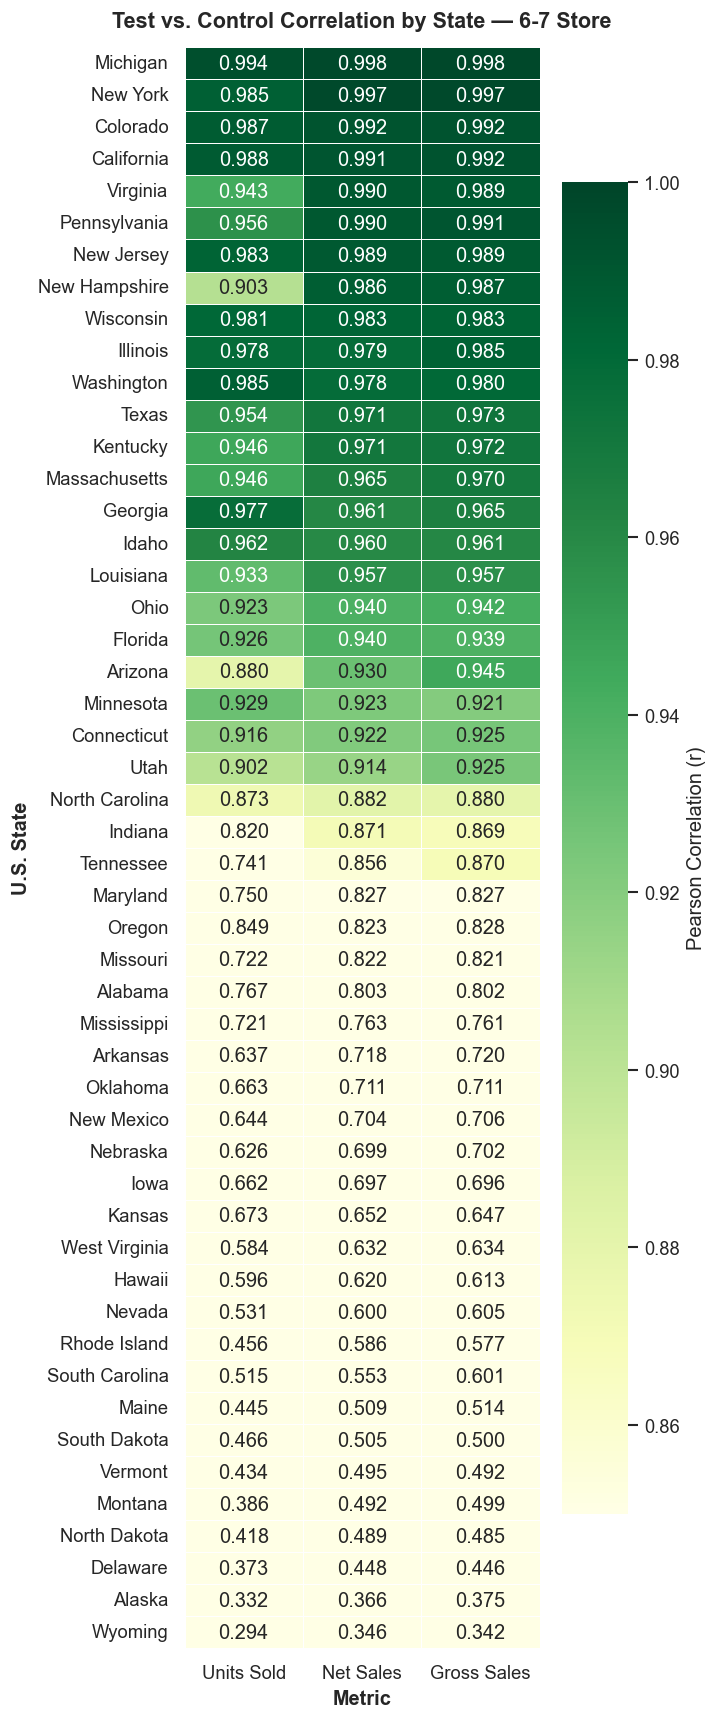

In [10]:
# Pearson correlation by state for each metric
state_metrics = []
state_group = df_tc.groupby(['state', 'dt_ref', 'flag'])[['qty_sold', 'net_sales', 'gross_sales']].sum().reset_index()

for st in state_group['state'].unique():
    sub = state_group[state_group['state'] == st]
    sub_piv = sub.pivot(index='dt_ref', columns='flag')

    row_dict = {'state': st}
    for m in ['qty_sold', 'net_sales', 'gross_sales']:
        t = sub_piv[(m, 'test')]
        c = sub_piv[(m, 'control')]
        row_dict[f'r_{m}'] = t.corr(c)
    state_metrics.append(row_dict)

df_state_corr = pd.DataFrame(state_metrics).sort_values('r_net_sales', ascending=False).set_index('state')

# Heatmap with Seaborn and the 7-Eleven-inspired palette
plt.figure(figsize=(6, max(3, 0.25 * len(df_state_corr) + 2)), dpi=120)
sns.heatmap(
    df_state_corr[['r_qty_sold', 'r_net_sales', 'r_gross_sales']],
    annot=True, fmt='.3f', cmap='YlGn', vmin=0.85, vmax=1.0, linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title('Test vs. Control Correlation by State — 6-7 Store', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Metric', fontweight='bold')
plt.ylabel('U.S. State', fontweight='bold')
plt.xticks([0.5, 1.5, 2.5], ['Units Sold', 'Net Sales', 'Gross Sales'], rotation=0)
plt.tight_layout()
plt.show()

## 7. Breakdown by Sales Region

We evaluate balance across the four U.S. sales regions (*Midwest, Northeast, South, and West*), comparing store counts, cumulative net sales, and regional time series. *In the saved run, only the South region (Florida) contains test and control stores.*

#### Seaborn

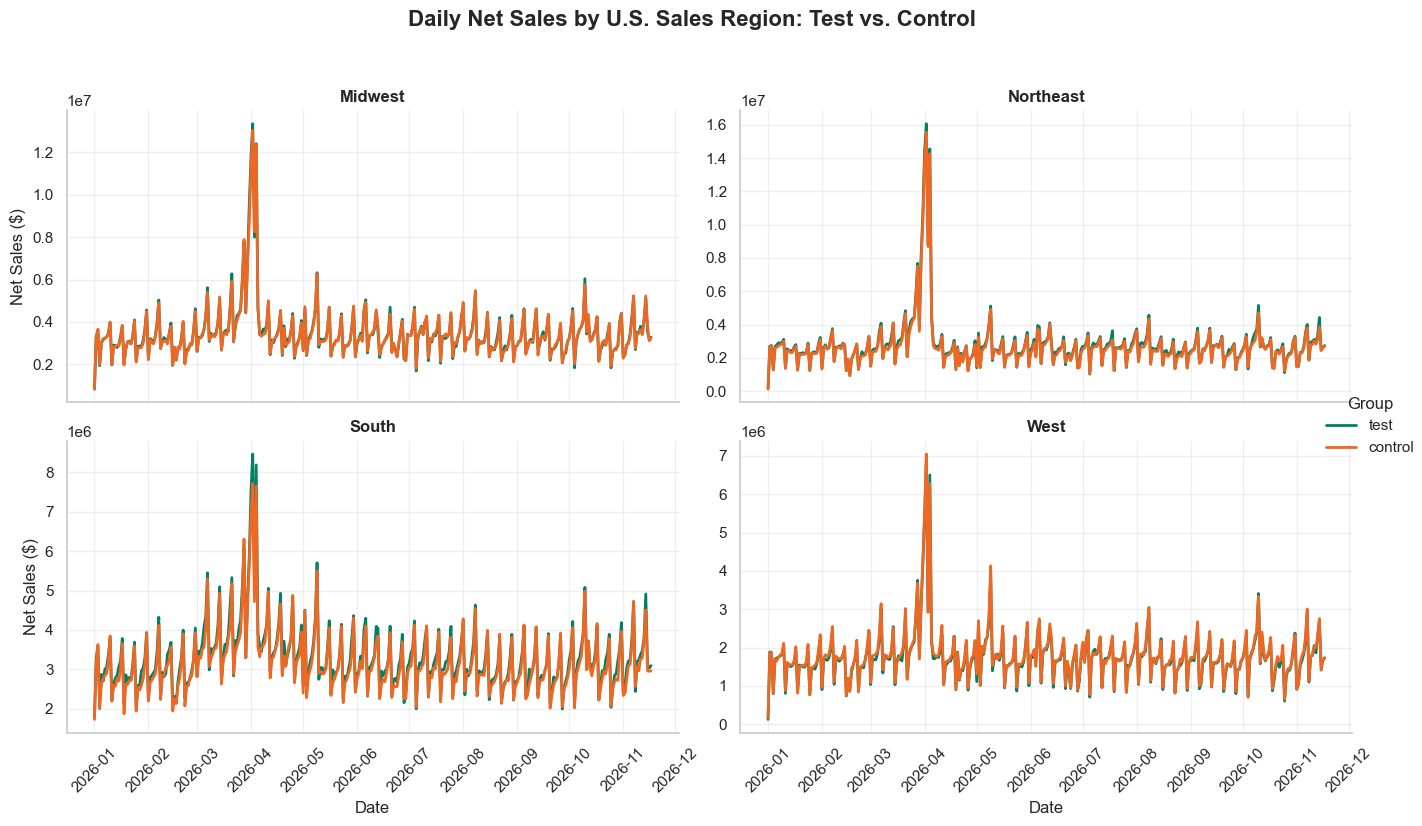

store_id            net_sales                   qty_sold  \
flag          control test         control            test    control   
sales_region                                                            
Midwest           152  152 1113582626.4900 1120061215.8000  142664508   
Northeast         119  119  863421114.9300  897478902.0600  113037990   
South             141  141 1018482631.5700 1057136952.5400  120379152   
West               82   82  579386912.7600  564948716.2900   66494852   

                         
flag               test  
sales_region             
Midwest       144619253  
Northeast     118144454  
South         124993160  
West           67593354

In [11]:
# 1. GROUPING BY REGION AND DATE
region_daily = (df_tc.groupby(['sales_region', 'dt_ref', 'flag'])['net_sales'] .sum() .reset_index())

# 2. DAILY NET SALES BY REGION
sns.set_theme(style='whitegrid', context='notebook')

g = sns.relplot(data=region_daily, x='dt_ref', y='net_sales', hue='flag', hue_order=['test', 'control'], kind='line', col='sales_region', col_wrap=2, palette={ 'test': PALETTE['test'], 'control': PALETTE['control']}, height=3.5, aspect=1.6, linewidth=2, facet_kws={'sharey': False})
g.set_axis_labels('Date', 'Net Sales ($)')
g.set_titles('{col_name}', fontweight='bold')
g.figure.suptitle('Daily Net Sales by U.S. Sales Region: Test vs. Control', fontsize=16, fontweight='bold', y=1.03)

g.figure.set_size_inches(14, 8)

for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)

g.legend.set_title('Group')
g.legend.set_bbox_to_anchor((1.02, 0.5))
plt.tight_layout()
plt.show()

# 3. CONSOLIDATED SUMMARY BY REGION
region_summary = (df_tc.groupby(['sales_region', 'flag']).agg({'store_id': 'nunique', 'net_sales': 'sum', 'qty_sold': 'sum'}).unstack())
display(region_summary)

#### Plotly

In [12]:
# Grouping by region and date
region_daily = df_tc.groupby(['sales_region', 'dt_ref', 'flag'])['net_sales'].sum().reset_index()

fig = px.line(
    region_daily, x='dt_ref', y='net_sales', color='flag',
    facet_col='sales_region', facet_col_wrap=2,
    color_discrete_map={'test': PALETTE['test'], 'control': PALETTE['control']},
    title='<b>Daily Net Sales by U.S. Sales Region: Test vs. Control</b>'
)

fig.update_layout(
    template='plotly_white',
    height=650,
    hovermode='x unified'
)
fig.show()

# Consolidated summary by region
region_summary = df_tc.groupby(['sales_region', 'flag']).agg({
    'store_id': 'nunique',
    'net_sales': 'sum',
    'qty_sold': 'sum'
}).unstack()

display(region_summary)

store_id            net_sales                   qty_sold  \
flag          control test         control            test    control   
sales_region                                                            
Midwest           152  152 1113582626.4900 1120061215.8000  142664508   
Northeast         119  119  863421114.9300  897478902.0600  113037990   
South             141  141 1018482631.5700 1057136952.5400  120379152   
West               82   82  579386912.7600  564948716.2900   66494852   

                         
flag               test  
sales_region             
Midwest       144619253  
Northeast     118144454  
South         124993160  
West           67593354

## 8. Weekly Seasonality and Purchase Patterns (Day-of-Week Analysis)

Convenience stores are highly sensitive to the day of the week: Fridays and weekends show pronounced peaks in beverages, snacks, and convenience items.

We check whether the control group closely mirrors the test group's intra-week pattern.

#### Seaborn

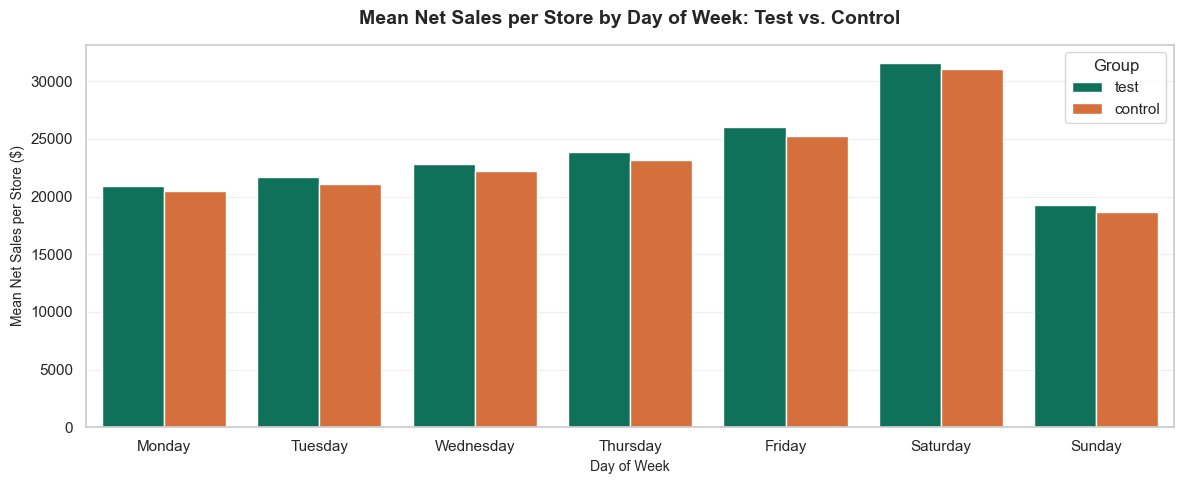

In [13]:
# 1. AGGREGATION BY DAY OF WEEK
df_tc['day_of_week'] = df_tc['dt_ref'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_agg = (df_tc.groupby(['day_of_week', 'flag'])[['net_sales', 'qty_sold']].mean().reset_index())
dow_agg['day_of_week'] = pd.Categorical(dow_agg['day_of_week'], categories=day_order, ordered=True)
dow_agg = dow_agg.sort_values('day_of_week')

# 2. MEAN NET SALES BY DAY OF WEEK
sns.set_theme(style='whitegrid', context='notebook')
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(data=dow_agg, x='day_of_week', y='net_sales', hue='flag', hue_order=['test', 'control'], order=day_order, palette={'test': PALETTE['test'], 'control': PALETTE['control']}, ax=ax)

ax.set_title('Mean Net Sales per Store by Day of Week: Test vs. Control', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Day of Week', fontsize=10)
ax.set_ylabel('Mean Net Sales per Store ($)', fontsize=10)
ax.legend(title='Group', loc='upper right', frameon=True)
ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

#### Plotly

In [14]:
df_tc['day_of_week'] = df_tc['dt_ref'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_agg = df_tc.groupby(['day_of_week', 'flag'])[['net_sales', 'qty_sold']].mean().reset_index()
dow_agg['day_of_week'] = pd.Categorical(dow_agg['day_of_week'], categories=day_order, ordered=True)
dow_agg = dow_agg.sort_values('day_of_week')

fig = px.bar(
    dow_agg, x='day_of_week', y='net_sales', color='flag', barmode='group',
    color_discrete_map={'test': PALETTE['test'], 'control': PALETTE['control']},
    title='<b>Mean Net Sales per Store by Day of Week: Test vs. Control</b>',
    labels={'net_sales': 'Mean Net Sales per Store ($)', 'day_of_week': 'Day of Week', 'flag': 'Group'}
)
fig.update_layout(template='plotly_white', height=480)
fig.show()